# Measure how much of main is MPI

You'll add up the time of the MPI calls of each run, divide it by the time of `main`, and draw that share as a heatmap over nodes and processes per node for each system.
It takes about 10 minutes of your time on a compute node.

## Before you start

Run the kernel inside an allocation and open the full sweep, as in [Measure the flop rate as processes share a node](06-flop-rate-as-processes-share-a-node.ipynb).

In [1]:
from dftracer.utils import Indexer, TraceViewer, col

TRACE = "/usr/workspace/genesis-wisdom/dftracer-traces/genesis-sweep/genesis.pfw.gz"
INDEX = "../data/full-index"
with Indexer(files=[TRACE], index_dir=INDEX) as ix:
    ix.ensure_indexed()
    runs = ix.rowset("runs")
tv = TraceViewer(TRACE, INDEX)
print(runs.shape)

(9624, 10)


In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("../figures", exist_ok=True)

## 1. Add up the MPI calls of each run

An MPI call has no traced children, so its `dur.sum` is all its own time.
Sum the `func` records whose name starts with `MPI_`, for each run.

In [3]:
calls = tv.filter((col("gtype") == "func") & col("name").str.startswith("MPI_")).collect()
mpi = calls.groupby("run")[["dur.sum"]].sum().rename(columns={"dur.sum": "mpi"})
main = tv.filter((col("gtype") == "func") & (col("path") == "main")).collect()
share = main[["run", "dur.sum"]].merge(mpi, on="run", how="left")
share = share.assign(mpi_share=share["mpi"].fillna(0) / share["dur.sum"])
share = share.merge(runs, on="run")
print(share.shape)

(8742, 13)


## 2. Read the share for one input

amg with `p1_n64x64x32` ran on every system, with the same problem size for each process.

In [4]:
amg = share[(share["app"] == "amg") & (share["unique_input"] == "p1_n64x64x32")]
heat = {}
for system in ["matrix", "tioga", "tuolumne"]:
    rows = amg[amg["system"] == system]
    heat[system] = rows.pivot_table(values="mpi_share", index="nodes", columns="ppn", aggfunc="median")
    print(system)
    print(heat[system])

matrix
   nodes         1         2         4         8        16        32        64
0      1  0.000986  0.023183  0.088879  0.095399  0.097460  0.170996  0.200995
1      2  0.039452  0.074976  0.127869  0.128768  0.127230  0.180929  0.241408
2      4  0.055231  0.089471  0.124394  0.167299  0.163132  0.214519       NaN
3      8  0.135392  0.155298  0.245535  0.216972  0.263125       NaN       NaN
tioga
   nodes         1         2         4         8        16        32
0      1  0.000504  0.010523  0.013084  0.094887  0.722754  0.669561
1      2  0.026539  0.031854  0.026912  0.114756  0.736864  0.732095
2      4  0.033072  0.044137  0.060084  0.126324  0.713294  0.711876
tuolumne
   nodes         1         2         4         8        16        32        64
0      1  0.000734  0.018976  0.022803  0.099650  0.302328  0.319192  0.381255
1      2  0.025395  0.041341  0.046298  0.137934  0.293709  0.336551  0.395875
2      4  0.037456  0.057564  0.077227  0.162629  0.323374       NaN  

Each value is the median over the runs of one setting, one for each counter set.

## 3. Draw the heatmaps

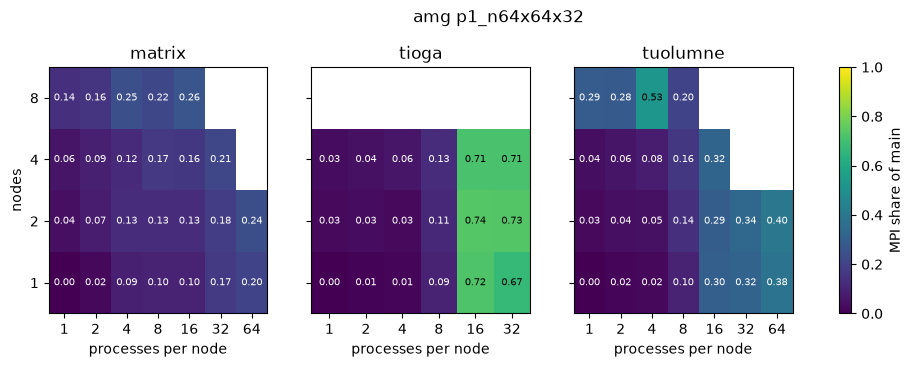

In [5]:
fig, axes = plt.subplots(1, len(heat), figsize=(4 * len(heat), 3.2), sharey=True)
for ax, (system, frame) in zip(axes, heat.items()):
    grid = frame.to_pandas().set_index("nodes")
    im = ax.imshow(grid.values, vmin=0, vmax=1, cmap="viridis", origin="lower", aspect="auto")
    ax.set_xticks(range(len(grid.columns)), grid.columns)
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set_xlabel("processes per node")
    ax.set_title(system)
    for (i, j), v in np.ndenumerate(grid.values):
        if v == v:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v < 0.5 else "black")
axes[0].set_ylabel("nodes")
fig.colorbar(im, ax=axes, label="MPI share of main")
fig.suptitle("amg p1_n64x64x32", y=1.06)
fig.savefig("../figures/mpi-share.png", dpi=120, bbox_inches="tight")
plt.show()

On matrix the share grows slowly, to about a quarter of `main` at the largest settings.
tuolumne reaches 0.3 to 0.4 from 16 processes per node, and 0.53 on 8 nodes with 4 processes per node.
On tioga it jumps from about 0.1 at 8 processes per node to about 0.7 at 16, on any number of nodes.
That's the setting where the flop rate of tioga fell on the previous page, so the processes spend the lost time waiting in MPI.

## 4. See which MPI calls take the time

In [6]:
at = calls.merge(amg[["run", "system", "nodes", "ppn"]], on="run")
tioga16 = at[(at["system"] == "tioga") & (at["nodes"] == 1) & (at["ppn"] == 16)]
display(tioga16.groupby("name")[["dur.sum"]].sum().nlargest(5, "dur.sum"))

,name,dur.sum
0,MPI_Waitall,2.088647e+09
1,MPI_Allreduce,7.075336e+08
2,MPI_Bcast,4.463637e+07
3,MPI_Iprobe,4.008051e+07
4,MPI_Scan,3.933462e+07


`MPI_Waitall` takes most of it, then `MPI_Allreduce`, so the processes mostly wait for messages to finish.

## What you built

You computed the MPI share of `main` for every run and found the settings where communication takes most of the time.

- Next: [Compare the three systems](08-compare-the-systems.ipynb)